# Part B: Lie Factor, in code

Tufte's Lie Factor compares the relative effect shown by the ink with the relative effect in the data. Honest graphics fall in the stated acceptance interval 0.95–1.05. The helper in `vizlib.py` is called once for each published graphic.

In [4]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt

DATA = Path.cwd()
if not (DATA / 'case07_lie_factor.csv').exists():
    DATA = DATA / 'Week 03'
sys.path.insert(0, str(DATA))
import vizlib

ACCEPTABLE_LOW = 0.95
ACCEPTABLE_HIGH = 1.05

lie_data = pd.read_csv(DATA / 'case07_lie_factor.csv')
def effect(start, end):
    return (end - start) / start

def verdict(lie):
    return 'Honest' if ACCEPTABLE_LOW <= lie <= ACCEPTABLE_HIGH else 'Distorted'

rows = []
for record in lie_data.itertuples(index=False):
    data_effect = effect(record.value_start, record.value_end)
    graphic_effect = (record.ink_end / record.ink_start) ** record.ink_dimension - 1
    lie = vizlib.lie_factor(
        record.value_start, record.value_end,
        record.ink_start, record.ink_end,
        record.ink_dimension,
    )
    rows.append({
        'graphic': record.chart_id,
        'subject': record.subject,
        'data_effect': data_effect,
        'graphic_effect': graphic_effect,
        'lie_factor': lie,
        'verdict': verdict(lie),
    })
audit = pd.DataFrame(rows).set_index('graphic')
print(audit.round(3).to_string())
assert len(audit) == 5
assert (audit['verdict'] == 'Honest').sum() == 1
assert audit.loc['C', 'verdict'] == 'Honest'

print(f'Acceptance interval: [{ACCEPTABLE_LOW}, {ACCEPTABLE_HIGH}]')
print('Rows removed: 0; all five published graphics are audited.')

                               subject  data_effect  graphic_effect  lie_factor    verdict
graphic                                                                                   
A                   Corporate tax rate        0.067           5.000       75.00  Distorted
B        Federal health budget (Rs bn)        0.500           1.250        2.50  Distorted
C               Export earnings ($ bn)        0.200           0.200        1.00     Honest
D                  Air-pollution index        0.500           0.125        0.25  Distorted
E           City population (millions)        3.000          15.000        5.00  Distorted
Acceptance interval: [0.95, 1.05]
Rows removed: 0; all five published graphics are audited.


## Interpretation

- **C is the only honest graphic**: its bars start at zero, so the length ratio matches the value ratio.
- **A exaggerates** the tax-rate change because the bars start at a 29.6% baseline; the visible tips change from 4 to 24 mm while the data changes only from 30 to 32.
- **B exaggerates** the budget change because a coin icon's area changes as the square of its linear scale.
- **D understates** the pollution increase because the measured bar height changes only from 8 to 9 cm while the index rises from 100 to 150.
- **E exaggerates** the population change because bubble area changes as the square of the radius, and the radius itself is proportional to population.

The area encodings are **B and E**. Leaving `ink_dimension=1` would treat a two-dimensional amount of ink as a one-dimensional length, understating the visual effect and producing the wrong Lie Factor.

In [5]:
dimension_check = []
for record in lie_data.itertuples(index=False):
    length_lie = vizlib.lie_factor(
        record.value_start, record.value_end,
        record.ink_start, record.ink_end,
        ink_dimension=1,
    )
    correct_lie = vizlib.lie_factor(
        record.value_start, record.value_end,
        record.ink_start, record.ink_end,
        ink_dimension=record.ink_dimension,
    )
    dimension_check.append({
        'graphic': record.chart_id,
        'declared_dimension': record.ink_dimension,
        'Lie Factor if treated as length': length_lie,
        'correct Lie Factor': correct_lie,
    })

print(pd.DataFrame(dimension_check).set_index('graphic').round(3).to_string())
print('Below-one distortion: D understates the pollution increase, which benefits anyone wanting the worsening air-pollution trend to appear smaller than it is.')

         declared_dimension  Lie Factor if treated as length  correct Lie Factor
graphic                                                                         
A                         1                            75.00               75.00
B                         2                             1.00                2.50
C                         1                             1.00                1.00
D                         1                             0.25                0.25
E                         2                             1.00                5.00
Below-one distortion: D understates the pollution increase, which benefits anyone wanting the worsening air-pollution trend to appear smaller than it is.


## Chart F: the dual-axis series

A single Lie Factor cannot be computed for Chart F. The formula assumes that one visual measurement scale encodes one comparable quantity. A dual-axis chart uses separate y-axis transformations for revenue and cost, so the apparent vertical separation depends on two unrelated scales; there is no single `ink_start` and `ink_end` effect to put in the numerator.


month  revenue_pkr_m  cost_pkr_m  profit_pkr_m
  Jan             52          44             8
  Feb             58          46            12
  Mar             61          47            14
  Apr             66          49            17
  May             71          51            20
  Jun             78          53            25

What the data actually shows:
Revenue exceeds cost in every month: True
Profit by month (PKR m): {'Jan': 8, 'Feb': 12, 'Mar': 14, 'Apr': 17, 'May': 20, 'Jun': 25}
Therefore ShaheenGo is profitable throughout Jan–Jun; there is no loss in the supplied series, including before May.


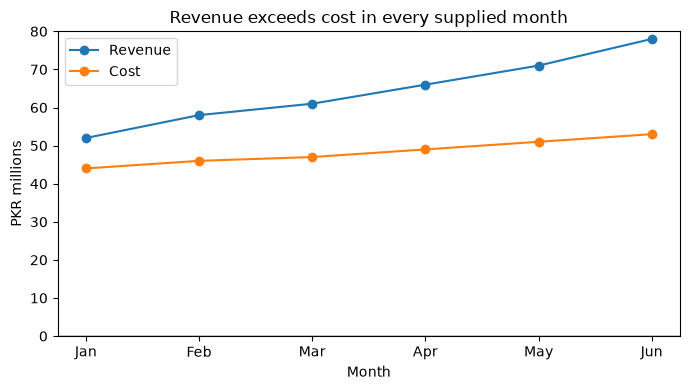

In [6]:
series = pd.read_csv(DATA / 'case07_dual_axis_series.csv')
series['profit_pkr_m'] = series['revenue_pkr_m'] - series['cost_pkr_m']
print(series.to_string(index=False))
print('\nWhat the data actually shows:')
print('Revenue exceeds cost in every month:', bool((series['profit_pkr_m'] > 0).all()))
print('Profit by month (PKR m):', series.set_index('month')['profit_pkr_m'].to_dict())
print('Therefore ShaheenGo is profitable throughout Jan–Jun; there is no loss in the supplied series, including before May.')

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(series['month'], series['revenue_pkr_m'], marker='o', label='Revenue')
ax.plot(series['month'], series['cost_pkr_m'], marker='o', label='Cost')
ax.axhline(0, color='black', linewidth=1)
ax.set_ylim(0, 80)
ax.set_xlabel('Month')
ax.set_ylabel('PKR millions')
ax.set_title('Revenue exceeds cost in every supplied month')
ax.legend()
fig.tight_layout()
fig.savefig(DATA / 'figures' / '07_part_b_common_scale.png', dpi=150, bbox_inches='tight')
plt.show()